# Heart Disease Prediction Using Machine Learning

## Project Overview
This project uses machine learning classification algorithms
to predict the presence of heart disease based on patient
health-related attributes.

## Objectives
- Explore and understand the heart disease dataset.
- Clean and preprocess the data.
- Perform exploratory data analysis.
- Train and compare machine learning models.
- Evaluate model performance using classification metrics.
- Save the best-performing model.

In [4]:
# Import required libraries

# Data manipulation

import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and preprocessing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine Learning models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

# Model saving
import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
# Load the dataset

# Load the heart disease dataset

df = pd.read_csv("heart.csv")

# Display the first 5 rows
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [6]:
# Dataset inspection

# 1. Check number of rows and columns
print("Dataset Shape:", df.shape)

# 2. Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Check data types and non-null values
print("\nDataset Information:")
df.info()

# 4. Statistical summary
print("\nStatistical Summary:")
df.describe()


Dataset Shape: (1025, 14)

Column Names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB

Statistical Summary:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [7]:
# Data cleaning

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Count duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Check dataset after removing duplicates
print("\nDataset Shape After Cleaning:", df.shape)

# Verify duplicates are removed
print("Remaining Duplicates:", df.duplicated().sum())

Missing Values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate Records: 723

Dataset Shape After Cleaning: (302, 14)
Remaining Duplicates: 0


Target Variable Distribution:
target
1    164
0    138
Name: count, dtype: int64

Target Percentage:
target
1    54.304636
0    45.695364
Name: proportion, dtype: float64


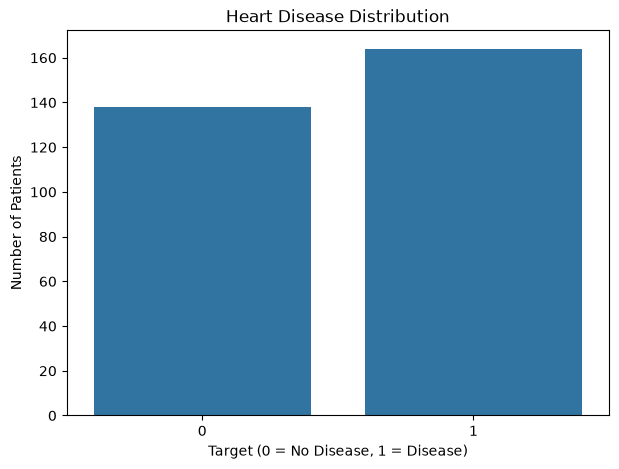

In [8]:
# Exploratory Data Analysis (EDA)
# Target Variable Analysis

# Check distribution of target variable
print("Target Variable Distribution:")
print(df['target'].value_counts())

# Check percentage distribution
print("\nTarget Percentage:")
print(df['target'].value_counts(normalize=True) * 100)

# Visualize target distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='target')

plt.title("Heart Disease Distribution")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Number of Patients")

plt.show()

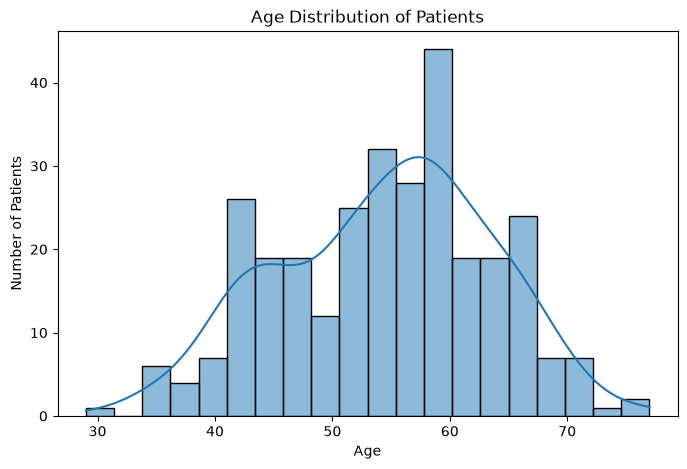

In [9]:
# Age distribution analysis

# Visualize age distribution
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='age', bins=20, kde=True)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

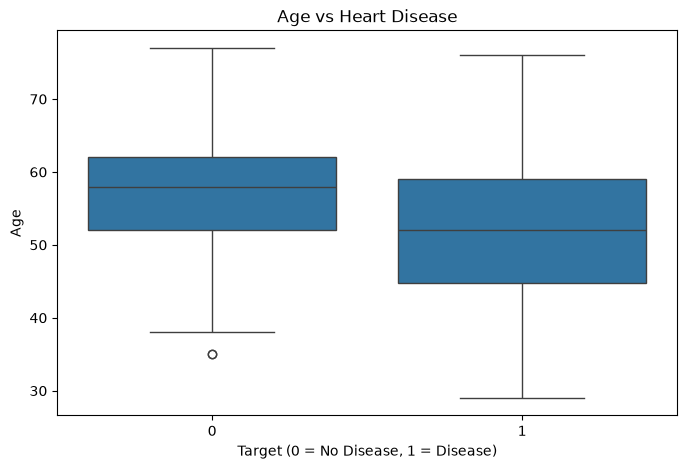

In [10]:
# Compare age with heart disease

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='target', y='age')

plt.title("Age vs Heart Disease")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Age")

plt.show()

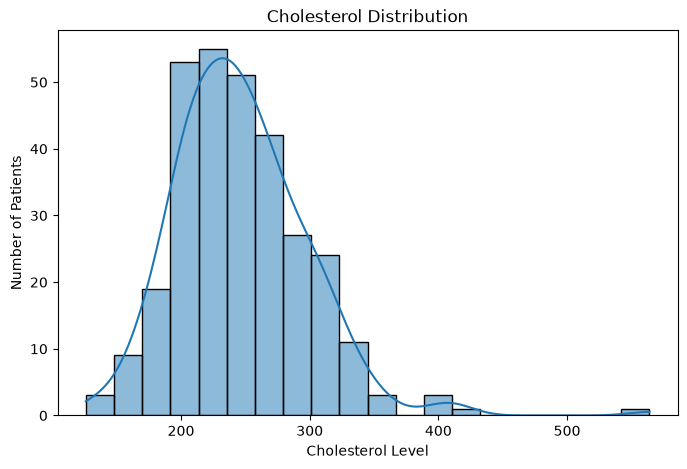

In [11]:
# Cholesterol analysis

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='chol', bins=20, kde=True)

plt.title("Cholesterol Distribution")
plt.xlabel("Cholesterol Level")
plt.ylabel("Number of Patients")

plt.show()

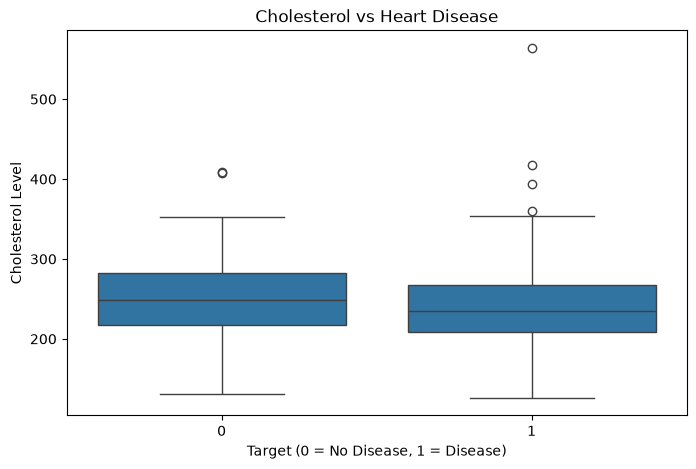

In [12]:
# Cholesterol vs Heart Disease

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='target', y='chol')

plt.title("Cholesterol vs Heart Disease")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Cholesterol Level")

plt.show()

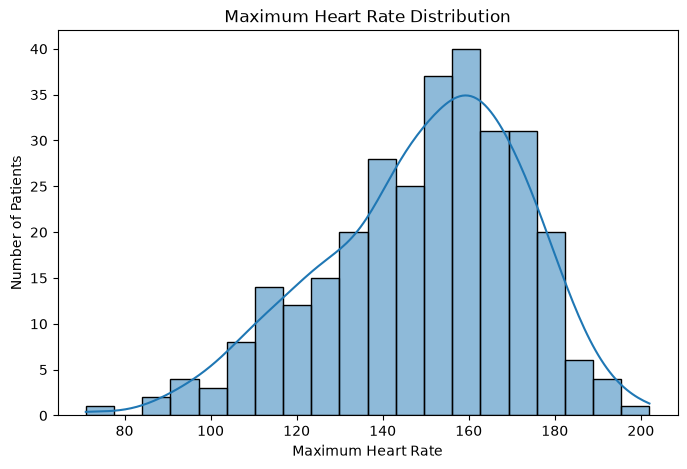

In [13]:
# Maximum Heart Rate Analysis

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='thalach', bins=20, kde=True)

plt.title("Maximum Heart Rate Distribution")
plt.xlabel("Maximum Heart Rate")
plt.ylabel("Number of Patients")

plt.show()

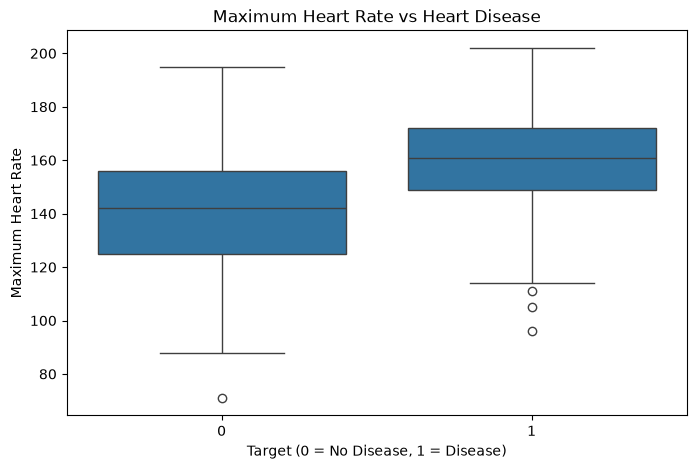

In [14]:
# Maximum Heart Rate vs Heart Disease

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='target', y='thalach')

plt.title("Maximum Heart Rate vs Heart Disease")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Maximum Heart Rate")

plt.show()

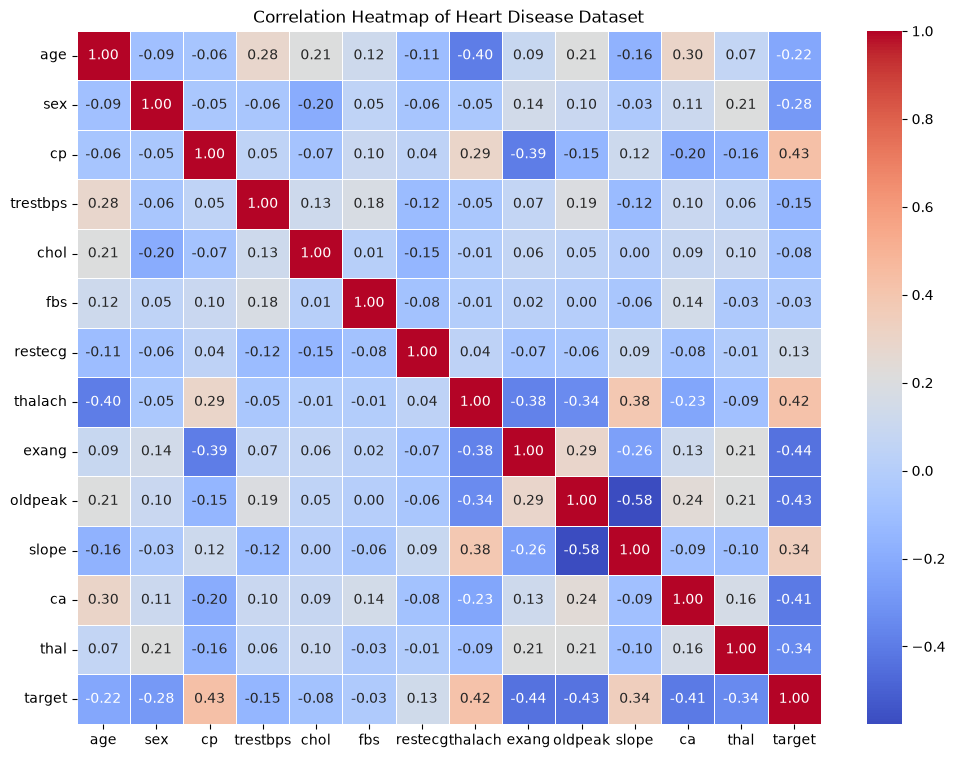

In [15]:
# Correlation heatmap

# Calculate correlation matrix
correlation_matrix = df.corr()

# Visualize correlation matrix
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Correlation Heatmap of Heart Disease Dataset")

plt.show()

In [16]:
# Prepare features and target

# Separate input features and target variable

X = df.drop('target', axis=1)
y = df['target']

# Display feature information
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(y.unique())

Features Shape: (302, 13)
Target Shape: (302,)

Input Features:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Target Classes:
[0 1]


In [17]:
# Train-test split

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

# Check target distribution
print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features: (241, 13)
Testing Features: (61, 13)

Training Target: (241,)
Testing Target: (61,)

Training Target Distribution:
target
1    131
0    110
Name: count, dtype: int64

Testing Target Distribution:
target
1    33
0    28
Name: count, dtype: int64


In [18]:
# Create preprocessing pipeline

# Identify numerical features
numerical_features = [
    'age',
    'trestbps',
    'chol',
    'thalach',
    'oldpeak'
]

# Identify categorical features
categorical_features = [
    'sex',
    'cp',
    'fbs',
    'restecg',
    'exang',
    'slope',
    'ca',
    'thal'
]

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)

# Combine both preprocessing methods
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)
print("\nPreprocessing pipeline created successfully!")


Numerical Features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

Categorical Features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']

Preprocessing pipeline created successfully!


In [19]:
# Logistic Regression

# Create Logistic Regression pipeline
logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=2000))
    ]
)

# Train the model
logistic_model.fit(X_train, y_train)

# Make predictions
y_pred_logistic = logistic_model.predict(X_test)

print("Logistic Regression Model Trained Successfully!")


Logistic Regression Model Trained Successfully!


In [20]:
# Evaluate Logistic Regression

# Evaluate Logistic Regression

print("LOGISTIC REGRESSION EVALUATION")
print("--------------------------------")

print("Accuracy:",
      accuracy_score(y_test, y_pred_logistic))

print("Precision:",
      precision_score(y_test, y_pred_logistic))

print("Recall:",
      recall_score(y_test, y_pred_logistic))

print("F1 Score:",
      f1_score(y_test, y_pred_logistic))

print("ROC-AUC:",
      roc_auc_score(
          y_test,
          logistic_model.predict_proba(X_test)[:, 1]
      ))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))

LOGISTIC REGRESSION EVALUATION
--------------------------------
Accuracy: 0.8360655737704918
Precision: 0.8484848484848485
Recall: 0.8484848484848485
F1 Score: 0.8484848484848485
ROC-AUC: 0.9047619047619048

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.82      0.82        28
           1       0.85      0.85      0.85        33

    accuracy                           0.84        61
   macro avg       0.83      0.83      0.83        61
weighted avg       0.84      0.84      0.84        61



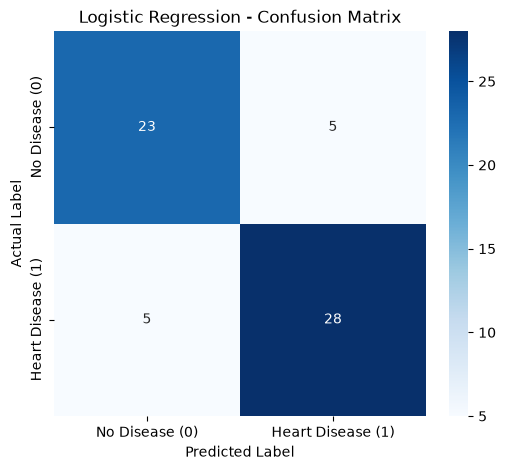

In [21]:
# Confusion Matrix

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred_logistic)

# Plot confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Disease (0)', 'Heart Disease (1)'],
    yticklabels=['No Disease (0)', 'Heart Disease (1)']
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [22]:
# Train Gaussian Naive Bayes


# Create Gaussian Naive Bayes pipeline
nb_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', GaussianNB())
    ]
)

# Train the model
nb_model.fit(X_train, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test)

print("Gaussian Naive Bayes Model Trained Successfully!")

Gaussian Naive Bayes Model Trained Successfully!


In [23]:
# Evaluate Gaussian Naive Bayes

# Evaluate Gaussian Naive Bayes

print("GAUSSIAN NAIVE BAYES EVALUATION")
print("--------------------------------")

print("Accuracy:",
      accuracy_score(y_test, y_pred_nb))

print("Precision:",
      precision_score(y_test, y_pred_nb))

print("Recall:",
      recall_score(y_test, y_pred_nb))

print("F1 Score:",
      f1_score(y_test, y_pred_nb))

print("ROC-AUC:",
      roc_auc_score(
          y_test,
          nb_model.predict_proba(X_test)[:, 1]
      ))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

GAUSSIAN NAIVE BAYES EVALUATION
--------------------------------
Accuracy: 0.8032786885245902
Precision: 0.8181818181818182
Recall: 0.8181818181818182
F1 Score: 0.8181818181818182
ROC-AUC: 0.8939393939393939

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.79      0.79        28
           1       0.82      0.82      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



In [24]:
# Model Comparison

# Create model comparison dataframe

model_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'Gaussian Naive Bayes'],

    'Accuracy': [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_nb)
    ],

    'Precision': [
        precision_score(y_test, y_pred_logistic),
        precision_score(y_test, y_pred_nb)
    ],

    'Recall': [
        recall_score(y_test, y_pred_logistic),
        recall_score(y_test, y_pred_nb)
    ],

    'F1 Score': [
        f1_score(y_test, y_pred_logistic),
        f1_score(y_test, y_pred_nb)
    ],

    'ROC-AUC': [
        roc_auc_score(y_test, logistic_model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, nb_model.predict_proba(X_test)[:, 1])
    ]
})

# Display comparison
model_comparison.round(4)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.8361,0.8485,0.8485,0.8485,0.9048
1,Gaussian Naive Bayes,0.8033,0.8182,0.8182,0.8182,0.8939


In [25]:
# Cross-validation

# 5-Fold Cross Validation

logistic_cv = cross_val_score(
    logistic_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

nb_cv = cross_val_score(
    nb_model,
    X,
    y,
    cv=5,
    scoring='accuracy'
)

# Display results
print("LOGISTIC REGRESSION")
print("Fold Scores:", logistic_cv)
print("Mean Accuracy:", logistic_cv.mean())
print("Standard Deviation:", logistic_cv.std())

print("\nGAUSSIAN NAIVE BAYES")
print("Fold Scores:", nb_cv)
print("Mean Accuracy:", nb_cv.mean())
print("Standard Deviation:", nb_cv.std())


LOGISTIC REGRESSION
Fold Scores: [0.86885246 0.85245902 0.91666667 0.81666667 0.8       ]
Mean Accuracy: 0.8509289617486339
Standard Deviation: 0.04101878271838753

GAUSSIAN NAIVE BAYES
Fold Scores: [0.7704918  0.78688525 0.95       0.73333333 0.8       ]
Mean Accuracy: 0.8081420765027323
Standard Deviation: 0.07437164492515519


In [26]:
# Corrected cross-validation

# Cross-validation using training data only

logistic_cv_train = cross_val_score(
    logistic_model,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

nb_cv_train = cross_val_score(
    nb_model,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy'
)

print("LOGISTIC REGRESSION")
print("Fold Scores:", logistic_cv_train)
print("Mean Accuracy:", logistic_cv_train.mean())
print("Standard Deviation:", logistic_cv_train.std())

print("\nGAUSSIAN NAIVE BAYES")
print("Fold Scores:", nb_cv_train)
print("Mean Accuracy:", nb_cv_train.mean())
print("Standard Deviation:", nb_cv_train.std())


LOGISTIC REGRESSION
Fold Scores: [0.85714286 0.77083333 0.8125     0.875      0.85416667]
Mean Accuracy: 0.8339285714285716
Standard Deviation: 0.03761791740315465

GAUSSIAN NAIVE BAYES
Fold Scores: [0.75510204 0.8125     0.75       0.8125     0.89583333]
Mean Accuracy: 0.8051870748299319
Standard Deviation: 0.05268363273385773


In [27]:
# Save the best model

# Select the best model
best_model = logistic_model

# Save the complete pipeline
joblib.dump(
    best_model,
    'heart_disease_model.pkl'
)

print("Best Model: Logistic Regression")
print("Model saved successfully!")


Best Model: Logistic Regression
Model saved successfully!


In [28]:
# Verify the saved model
# Load the saved model
loaded_model = joblib.load('heart_disease_model.pkl')

print("Model loaded successfully!")

# Check model type
print("\nModel Details:")
print(loaded_model)

Model loaded successfully!

Model Details:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'trestbps', 'chol',
                                                   'thalach', 'oldpeak']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['sex', 'cp', 'fbs',
                                                   'restecg', 'exang', 'slope',
                                                   'ca', 'thal'])])),
                ('classifier', LogisticRegression(max_iter=2000))])


In [29]:
# Make predictions on new patient records

# Create sample patient records
sample_patients = pd.DataFrame([
    [55, 1, 1, 120, 200, 0, 1, 170, 0, 1.0, 2, 0, 2],
    [70, 1, 0, 180, 350, 1, 0, 90, 1, 5.0, 0, 3, 3]
], columns=X.columns)

# Make predictions
predictions = loaded_model.predict(sample_patients)

# Display results
for i, prediction in enumerate(predictions):
    result = "Heart Disease (1)" if prediction == 1 else "No Heart Disease (0)"
    print(f"Patient {i+1}: {result}")


Patient 1: Heart Disease (1)
Patient 2: No Heart Disease (0)


In [30]:
# Create sample patient records
sample_patients = pd.DataFrame([
    [55, 1, 1, 120, 200, 0, 1, 170, 0, 1.0, 2, 0, 2],
    [70, 1, 0, 180, 350, 1, 0, 90, 1, 5.0, 0, 3, 3]
], columns=X.columns)

# Make predictions
predictions = loaded_model.predict(sample_patients)

# Display results
for i, prediction in enumerate(predictions):
    result = "Heart Disease (1)" if prediction == 1 else "No Heart Disease (0)"
    print(f"Patient {i+1}: {result}")

Patient 1: Heart Disease (1)
Patient 2: No Heart Disease (0)


<Figure size 800x600 with 0 Axes>

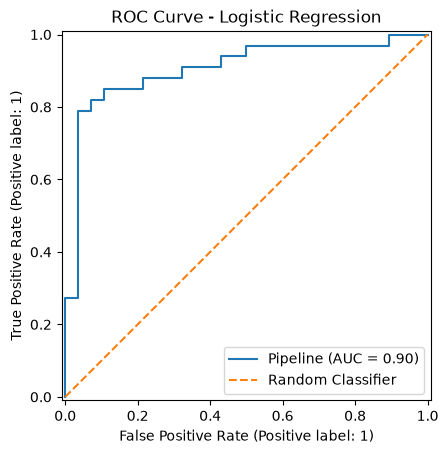

In [31]:
# ROC Curve

# Plot ROC curve
plt.figure(figsize=(8, 6))

RocCurveDisplay.from_estimator(
    loaded_model,
    X_test,
    y_test
)

plt.title("ROC Curve - Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.legend()
plt.show()

# Project conclusion

## Conclusion

The Heart Disease Prediction project uses machine learning classification algorithms to predict the presence of heart disease based on patient health-related attributes.

The dataset initially contained 1,025 records and 14 columns. After removing duplicate records, 302 unique records were retained. Exploratory Data Analysis was performed using histograms, boxplots, and a correlation heatmap.

Two machine learning algorithms were implemented:
- Logistic Regression
- Gaussian Naive Bayes

Both models were evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and 5-fold cross-validation.

Logistic Regression performed better than Gaussian Naive Bayes in the evaluated results, achieving:
- Accuracy: 83.61%
- Precision: 84.85%
- Recall: 84.85%
- F1-score: 84.85%
- ROC-AUC: 90.48%

The Logistic Regression pipeline was saved using Joblib and successfully loaded for predictions on new sample records.

This project demonstrates the application of data preprocessing, exploratory data analysis, classification algorithms, model evaluation, and model deployment basics.

**Disclaimer:** This project is developed for educational purposes and is not intended for medical diagnosis or clinical decision-making.